# 19 - Separate movie and whole-series recommendation rankings

**Question:** Do movie and TV recommendations improve when each type has its own ranking, tuning, and possibly training basis, while users keep one shared rating history?

This is a bounded follow-up to [notebook 18](18_filmaffinity_tv_ranking_policy.ipynb). The intended app views are **Movies**, **TV series**, and **Both**. Movies and TV request their own ranked candidate lists. Both can show two sections with ten movie recommendations and ten whole-series recommendations, without forcing the two types into a single ten-slot feed.

Separate lists do not automatically demonstrate a better model: giving both types ten positions doubles the total budget compared with a mixed list of ten. This notebook measures model changes within each fixed ten-item type list and adds a separate comparison at an equal total budget of twenty titles.

## Prespecified data and evaluation boundaries

- Reuse notebook 18's frozen FilmAffinity source identities, train/validation split, and **12 confirmed season-unit exclusions**. Do not merge season scores into whole-series scores or rewrite earlier notebooks and artifacts.
- Keep the same eligible training candidates: **8,995 movies** and **1,715 provisional whole-series entries**. Fit only on corrected training ratings and metadata for training-catalog titles. Validation-only titles must not enter vocabularies, priors, or candidate construction.
- A like remains **8/10 or higher**. Exclude every title in the user's training history, including low ratings. Unobserved titles are not explicit dislikes.
- Keep the eligible validation cohorts fixed across variants: **3,830 movie-positive users** and **972 TV-positive users**. Include users without a same-type training like and retain all eligible held-out positives in Recall and ideal-DCG denominators, even when unavailable as candidates.
- Preserve the source-namespaced user identities. The inherited training cohort contains 5,505 users; its original minimum-history/date eligibility was determined before the season-unit correction, so no new minimum-history claim is made after cleanup.
- Use training feedback only for feature fitting, popularity, Bayesian prior centers, and history profiles. Read no reserved-test feedback, earlier MovieLens feedback, full raw rating archive, API credentials, or app data.

The recommendation type filter is applied **before choosing the top ten**. Selecting TV therefore ranks the TV candidate set directly rather than hiding movies in an already truncated mixed list.

## Prespecified model comparisons

Compare three fresh training/profile designs using the same corrected feedback and candidate cohorts:

1. **Clean shared basis, shared history:** refit the common TF-IDF, genre/cast features, collaborative basis, and training-only Bayesian prior on corrected training data. Build the user's profile from eligible likes of both movies and series.
2. **Clean shared basis, same-type history:** use that identical shared fitted basis, but build each profile using likes of the requested type only. This isolates the effect of cross-type history without changing encoders.
3. **Independent type training:** refit the movie and TV feature vocabularies, genre/cast IDF, collaborative basis, and training-prior center on their own type's training data. Use same-type history. Keep the supplied full user namespace, including users with no training feedback of that type.

The inherited personal hybrid weights remain **p=0.25 for synopsis, m=0.25 for metadata, q=0.10 for quality**. Do not reopen the earlier multidimensional weight search. For each fresh design and type, test only **personal/popularity blend weights 0, 0.25, 0.5, and 1**. Weight 0 is training popularity; weight 1 is the personal hybrid. Components are scaled using unseen candidates of the requested type before combining them.

Keep the exact notebook-18 shelf controls as references, preserving their original full-catalog component scaling: the movie personal hybrid and the TV blend previously selected for its shelf. Also retain the frozen pure-personal TV ranking needed for the budget comparison. These controls distinguish rebuilding/tuning a ranker from merely changing which titles are displayed.

This is roughly twelve new candidate settings per type plus the frozen controls. Select the movie and TV rankers **independently**, by Recall@10, then NDCG@10, then the prespecified preference for the simpler family and lower personalization weight. A tied popularity ranking should not be interpreted as evidence that separate training helps.

## Equal-budget comparison and interpretation

For a Both view, ten movies plus ten series means twenty distinct title positions. Compare the following with that same total budget:

- The frozen corrected personal hybrid's **mixed top twenty**.
- That same frozen personal scorer's **ten movies plus ten series**. This holds its scoring rule fixed and isolates allocation into two sections.
- Notebook 18's separate shelf settings, **ten plus ten**.
- Notebook 19's independently selected movie and TV settings, **ten plus ten**.

Measure overall and per-domain **Recall from the twenty-title union**. Do not invent a cross-section NDCG: two side-by-side sections have no natural movie-versus-series ordering. Each individual shelf still has its own valid NDCG@10. Older mixed top-ten results may be shown only as a different-budget reference, not as the denominator for a claimed model improvement.

Within-type Recall@10 changes against the frozen shelf controls address the model question. The equal-budget comparison addresses the presentation/allocation question. Neither comparison by itself proves that every user prefers the resulting recommendations.

In [1]:
from pathlib import Path
import sys

ROOT = next(
    (path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (path / 'scripts/filmaffinity_experiment.py').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from inside the movie-recommendation-system project.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.filmaffinity_separate_rankers import run_experiment

report = run_experiment(ROOT)

Verifying frozen sources, split and notebook18 eligibility corrections...
Refitting from 173,022 clean training ratings, no validation fitting...
movie: validated 128/3,830 users, 13 rankers.
movie: validated 1,024/3,830 users, 13 rankers.
movie: validated 2,048/3,830 users, 13 rankers.
movie: validated 3,072/3,830 users, 13 rankers.
movie: validated 3,830/3,830 users, 13 rankers.
whole_series: validated 128/972 users, 14 rankers.
whole_series: validated 972/972 users, 14 rankers.
Selected independently: {'movie': {'ranker': 'independent; alpha=1', 'family': 'independent', 'alpha': 1.0, 'complexity': 3}, 'whole_series': {'ranker': 'Notebook18 shelf control', 'family': 'frozen', 'alpha': 0.25, 'complexity': 0}}; completed in 76.7s.


## What this run found

The study refit from **173,022 corrected training ratings** and compared **27 ranking settings**. Candidates and held-out cohorts remain fixed: **8,995 movies / 3,830 movie-positive users**, and **1,715 series / 972 series-positive users**. All four frozen18 control checks reproduced to floating-point tolerance.

### Model quality within the same ten slots

| Ranker design | Movie Recall@10 | TV Recall@10 |
|---|---:|---:|
| Previous best separate shelves (18 controls) | 4.887% | **15.650%** |
| Refit shared basis, all-type history (best alpha per type) | 4.922% | 15.547% |
| Same shared basis, same-type history (best alpha per type) | 4.937% | 15.615% |
| Independently fitted type basis (best alpha per type) | **4.977%** | 15.478% |

For movies, independent fitting with alpha=1 has the highest observed Recall. Its gain over the old shelf is about **0.090 percentage points (1.84% relative)**. The descriptive paired bootstrap interval for the Recall difference is approximately **-0.045 to +0.236 percentage points**, spanning zero. Both selection and intervals use the same validation set. This is a small validation lead, not confirmed improvement.

For TV, **the previous 25% personal / 75% popularity shelf remains best**. Neither fully independent TV fitting nor removing movie history beats it at the competitive blend weights. The chosen movie pipeline and TV pipeline therefore use different fitting/profile strategies; a common rating store does not require identical ranking logic.

The family-best table independently tunes alpha within each family. Use the fixed-alpha table below to isolate history/basis changes without also changing the blend weight. Binary item-user cosine rows are identical when fitted from the same item ratings and fixed user namespace; type-specific fitting changes the content vocabulary/IDF and Bayesian-prior center rather than introducing a new collaborative algorithm.

### Separate lists versus one mixed list, at twenty total titles

| Twenty-title presentation | Overall Recall | Movie Recall | TV Recall |
|---|---:|---:|---:|
| Original corrected personal scorer, mixed20 | **7.02%** | **7.75%** | 1.13% |
| Same scorer, ten movies plus ten series | 5.26% | 4.89% | 7.63% |
| Best18 shelves, ten plus ten | 6.22% | 4.89% | **15.65%** |
| Selected19 shelves, ten plus ten | 6.28% | 4.98% | **15.65%** |

Separate sections make TV recommendations accessible, but **do not improve overall recall at the same total budget** in this study. They allocate ten positions to each kind, while the mixed scorer favors movies. The first two rows hold the scorer fixed and isolate the allocation effect. The later rows also change the TV blend and/or movie model. No NDCG is assigned across the unordered pair of sections.

The product choice can still be **Movies / TV series / Both**, with Both showing two separately ranked sections. That lets the viewer choose a format without forcing a global movie-versus-series score comparison. The experiment does not establish that all users prefer that layout or that two completely isolated training systems are necessary.

### History, fallback and remaining limits

Same-type TV profiles are empty for **320 of 972** TV-positive users, versus **16** with shared history. Empty profiles fall back to training popularity, even at alpha=1. Part of a same-type-history gain can therefore reflect a stronger fallback rather than better personalized inference. History-bin differences are observational.

This remains repeated validation on review-associated FilmAffinity scores, with review-date proxies, current metadata, and provisional units beyond the 12 confirmed season exclusions. The inherited cohort is unchanged. Earlier notebooks and app files are preserved, no paid calls were made, and the reserved test remains closed.


## Recorded scope, protocol, and population

The helper records the actual input hashes, model grid, selection rule, fitting boundaries, and retained population. Review these before interpreting the leaderboards. Current metadata, review-publication date proxies, review-associated score selection, and provisional title units remain limitations.

In [2]:
import pandas as pd
from IPython.display import display

OUTPUT = ROOT / 'data/processed/notebook19_filmaffinity'
display(report.get('scope', {}))
study_contract = report.get('study_plan', {})
display({key: value for key, value in study_contract.items()
         if key not in {'input_sha256', 'user_ids', 'candidate_ids'}})
display(report.get('dataset', {}))

{'evaluation_split': 'validation',
 'test_feedback_read': False,
 'raw_rating_archive_read': False,
 'paid_api_calls': False,
 'app_changed': False,
 'training': 'Refit clean joint and independent-domain bases using frozen training only; frozen18 controls are not refit',
 'cf_interpretation': 'Binary item-user cosine is unchanged for the same items/users; per-type fit differences concern content IDF/vocabulary and training prior, not a new CF algorithm',
 'history_interpretation': 'Shared_all vs shared_same isolates profile history at fixed alpha; independent vs shared_same changes the type-specific content/prior fitting package',
 'fallback_interpretation': 'Empty personal profiles fall back to training counts even at alpha1; fallback counts accompany every row',
 'budget': 'Per-type model gains require the same ten slots per type. Both has twenty total titles; equal-budget union Recall is a separate allocation comparison',
 'limits': 'Repeated validation, review-selected feedback, pu

{'experiment': 'notebook19_separate_rankers',
 'like_threshold': 8.0,
 'rankers': {'movie': [{'ranker': 'Notebook18 shelf control',
    'family': 'frozen',
    'alpha': 1.0,
    'complexity': 0},
   {'ranker': 'shared_all; alpha=0',
    'family': 'shared_all',
    'alpha': 0.0,
    'complexity': 1},
   {'ranker': 'shared_all; alpha=0.25',
    'family': 'shared_all',
    'alpha': 0.25,
    'complexity': 1},
   {'ranker': 'shared_all; alpha=0.5',
    'family': 'shared_all',
    'alpha': 0.5,
    'complexity': 1},
   {'ranker': 'shared_all; alpha=1',
    'family': 'shared_all',
    'alpha': 1.0,
    'complexity': 1},
   {'ranker': 'shared_same; alpha=0',
    'family': 'shared_same',
    'alpha': 0.0,
    'complexity': 2},
   {'ranker': 'shared_same; alpha=0.25',
    'family': 'shared_same',
    'alpha': 0.25,
    'complexity': 2},
   {'ranker': 'shared_same; alpha=0.5',
    'family': 'shared_same',
    'alpha': 0.5,
    'complexity': 2},
   {'ranker': 'shared_same; alpha=1',
    'family':

{'clean_training_ratings': 173022,
 'training_users': 5505,
 'training_candidates': 10710,
 'movie_candidates': 8995,
 'series_candidates': 1715,
 'movie_validation_users': 3830,
 'series_validation_users': 972,
 'new_rankers_per_type': 12,
 'total_rankers': 27}

## Coverage and frozen-control checks

Keep unavailable eligible likes in the metric denominators. Coverage describes the opportunity to recommend relevant titles, not a score to maximize by deleting difficult targets. Fixed control checks help detect accidental changes to the inherited baseline while the new training/profile designs are evaluated separately.

In [3]:
display(report.get('coverage', {}))
display(report.get('parity_checks', {}))

def show_saved_table(filename):
    frame = pd.read_csv(OUTPUT / filename)
    with pd.option_context('display.max_columns', None, 'display.max_rows', 40):
        display(frame)
    return frame

[{'task': 'mixed',
  'users': 4143,
  'positives': 17378,
  'available': 17184,
  'mean_available_fraction': 0.9881582743311027,
  'mean_recall_ceiling_at_10': 0.956067882215915},
 {'task': 'movie',
  'users': 3830,
  'positives': 15625,
  'available': 15520,
  'mean_available_fraction': 0.9935298984969144,
  'mean_recall_ceiling_at_10': 0.9621949343274899},
 {'task': 'whole_series',
  'users': 972,
  'positives': 1753,
  'available': 1664,
  'mean_available_fraction': 0.9583027026699866,
  'mean_recall_ceiling_at_10': 0.9567580457890724}]

[{'kind': 'movie',
  'control': 'Notebook18 shelf control',
  'users': 3830,
  'max_absolute_error': 9.71445146547012e-17,
  'passed': True},
 {'kind': 'whole_series',
  'control': 'Notebook18 shelf control',
  'users': 972,
  'max_absolute_error': 8.326672684688674e-17,
  'passed': True},
 {'kind': 'whole_series',
  'control': 'Frozen shared personal',
  'users': 972,
  'max_absolute_error': 9.71445146547012e-17,
  'passed': True},
 {'control': 'Frozen18 mixed10',
  'users': 4143,
  'max_absolute_error': 9.71445146547012e-17,
  'passed': True}]

## Movie and TV quality within separate ten-item lists

Each domain below has its own fixed candidate set, user cohort, relevance labels, and ten recommendation positions for every variant. A new ranker improves the observed within-type metric only if it beats the frozen control under that same budget and protocol. Compare shared-history and same-type-history rows to test the value of cross-type profile information; compare the same-type shared basis with independently trained type bases to test separate fitting.

In [4]:
print('Movie-only ranking variants:')
movie_leaderboard = show_saved_table('movie_leaderboard.csv')
print('Whole-series-only ranking variants:')
tv_leaderboard = show_saved_table('tv_leaderboard.csv')

Movie-only ranking variants:
Whole-series-only ranking variants:


,kind,ranker,family,alpha,complexity,users,recall_at_10,ndcg_at_10,empty_profile_users
0,movie,independent; alpha=1,independent,1.00,3,3830,0.049774,0.037441,114
1,movie,shared_same; alpha=1,shared_same,1.00,2,3830,0.049369,0.037197,114
2,movie,shared_all; alpha=1,shared_all,1.00,1,3830,0.049217,0.037124,82
3,movie,Notebook18 shelf control,frozen,1.00,0,3830,0.048875,0.037087,82
4,movie,shared_all; alpha=0.5,shared_all,0.50,1,3830,0.044297,0.032939,82
5,movie,independent; alpha=0.5,independent,0.50,3,3830,0.044098,0.032814,114
6,movie,shared_same; alpha=0.5,shared_same,0.50,2,3830,0.043955,0.032977,114
7,movie,independent; alpha=0.25,independent,0.25,3,3830,0.035227,0.024662,114
8,movie,shared_same; alpha=0.25,shared_same,0.25,2,3830,0.035222,0.024644,114
9,movie,shared_all; alpha=0.25,shared_all,0.25,1,3830,0.035107,0.024614,82


,kind,ranker,family,alpha,complexity,users,recall_at_10,ndcg_at_10,empty_profile_users
0,whole_series,Notebook18 shelf control,frozen,0.25,0,972,0.156498,0.089369,16
1,whole_series,shared_same; alpha=0.25,shared_same,0.25,2,972,0.156147,0.090121,320
2,whole_series,shared_all; alpha=0.25,shared_all,0.25,1,972,0.155470,0.088891,16
3,whole_series,independent; alpha=0.25,independent,0.25,3,972,0.154775,0.089640,320
4,whole_series,shared_all; alpha=0,shared_all,0.00,1,972,0.153394,0.086824,16
5,whole_series,shared_same; alpha=0,shared_same,0.00,2,972,0.153394,0.086824,320
6,whole_series,independent; alpha=0,independent,0.00,3,972,0.153394,0.086824,320
7,whole_series,shared_all; alpha=0.5,shared_all,0.50,1,972,0.152470,0.090407,16
8,whole_series,shared_same; alpha=0.5,shared_same,0.50,2,972,0.149974,0.088889,320
9,whole_series,independent; alpha=0.5,independent,0.50,3,972,0.148956,0.088764,320


## Independently selected rankers

The movie winner and TV winner may use different profile designs or popularity weights. Their selection is still based on validation reused in previous experiments. A selected difference is exploratory and requires a later frozen test or prospective evaluation before a general accuracy claim.

In [5]:
display(report.get('selections', {}))

{'movie': {'ranker': 'independent; alpha=1',
  'family': 'independent',
  'alpha': 1.0,
  'complexity': 3,
  'kind': 'movie',
  'users': 3830,
  'recall_at_10': 0.049774196325214126,
  'ndcg_at_10': 0.037441097336917764,
  'empty_profile_users': 114},
 'whole_series': {'ranker': 'Notebook18 shelf control',
  'family': 'frozen',
  'alpha': 0.25,
  'complexity': 0,
  'kind': 'whole_series',
  'users': 972,
  'recall_at_10': 0.15649843983177317,
  'ndcg_at_10': 0.08936877097949898,
  'empty_profile_users': 16}}

## History-depth diagnostics

Inspect cohort sizes and per-type quality for sparse and richer training histories. Users without a same-type like must remain in their eligible validation cohort; a deterministic training-popularity fallback is part of the evaluated policy. History-group differences are observational and do not establish that adding more ratings causes an improvement.

In [6]:
history_bin_table = show_saved_table('history_bin_metrics.csv')
display(report.get('history_bins', {}))

,kind,ranker,family,alpha,history_bin,users,recall_at_10,ndcg_at_10,empty_profile_users
0,movie,Notebook18 shelf control,frozen,1.0,1-4,1303,0.037419,0.022449,0
1,movie,Notebook18 shelf control,frozen,1.0,5+,2413,0.056541,0.046304,0
2,movie,Notebook18 shelf control,frozen,1.0,0,114,0.017544,0.009312,82
3,movie,shared_all; alpha=0,shared_all,0.0,1-4,1303,0.032738,0.016933,0
4,movie,shared_all; alpha=0,shared_all,0.0,5+,2413,0.031783,0.025135,0
...,...,...,...,...,...,...,...,...,...
76,whole_series,independent; alpha=0.5,independent,0.5,0,320,0.187500,0.104981,320
77,whole_series,independent; alpha=0.5,independent,0.5,5+,163,0.115538,0.071626,0
78,whole_series,independent; alpha=1,independent,1.0,1-4,489,0.058798,0.032712,0
79,whole_series,independent; alpha=1,independent,1.0,0,320,0.187500,0.104981,320


[{'kind': 'movie',
  'ranker': 'independent; alpha=1',
  'family': 'independent',
  'alpha': 1.0,
  'history_bin': '1-4',
  'users': 1303,
  'recall_at_10': 0.0379490552936447,
  'ndcg_at_10': 0.022649313024329244,
  'empty_profile_users': 0},
 {'kind': 'movie',
  'ranker': 'independent; alpha=1',
  'family': 'independent',
  'alpha': 1.0,
  'history_bin': '5+',
  'users': 2413,
  'recall_at_10': 0.057682367541629115,
  'ndcg_at_10': 0.046840445426252486,
  'empty_profile_users': 0},
 {'kind': 'movie',
  'ranker': 'independent; alpha=1',
  'family': 'independent',
  'alpha': 1.0,
  'history_bin': '0',
  'users': 114,
  'recall_at_10': 0.017543859649122806,
  'ndcg_at_10': 0.007555729089006895,
  'empty_profile_users': 114},
 {'kind': 'whole_series',
  'ranker': 'Notebook18 shelf control',
  'family': 'frozen',
  'alpha': 0.25,
  'history_bin': '1-4',
  'users': 489,
  'recall_at_10': 0.15465478624987827,
  'ndcg_at_10': 0.08940019165382085,
  'empty_profile_users': 0},
 {'kind': 'whole

## Both view at an equal total recommendation budget

The twenty-title union comparison keeps the total number of recommendation positions fixed. It separates gains due to giving TV its own section from gains due to changes in the selected rankers. Union Recall does not require an arbitrary order between the two sections. Individual-domain NDCG remains a shelf metric.

In [7]:
equal_budget_table = show_saved_table('equal_budget_comparison.csv')
display(report.get('budget_comparison', {}))

,view,total_budget,mixed_users,mixed_recall_at_budget,movie_users,movie_recall_at_budget,tv_users,tv_recall_at_budget
0,Frozen shared mixed20,20,4143,0.070220,3830,0.077522,972,0.011343
1,Frozen personal shelves 10+10,20,4143,0.052621,3830,0.048875,972,0.076260
2,Notebook18 best shelves 10+10,20,4143,0.062156,3830,0.048875,972,0.156498
3,Selected19 shelves 10+10,20,4143,0.062839,3830,0.049774,972,0.156498


[{'view': 'Frozen shared mixed20',
  'total_budget': 20,
  'mixed_users': 4143,
  'mixed_recall_at_budget': 0.0702197586894251,
  'movie_users': 3830,
  'movie_recall_at_budget': 0.07752235958794403,
  'tv_users': 972,
  'tv_recall_at_budget': 0.011342592592592593},
 {'view': 'Frozen personal shelves 10+10',
  'total_budget': 20,
  'mixed_users': 4143,
  'mixed_recall_at_budget': 0.05262072318277933,
  'movie_users': 3830,
  'movie_recall_at_budget': 0.04887452789521241,
  'tv_users': 972,
  'tv_recall_at_budget': 0.07625970370447303},
 {'view': 'Notebook18 best shelves 10+10',
  'total_budget': 20,
  'mixed_users': 4143,
  'mixed_recall_at_budget': 0.06215600179668549,
  'movie_users': 3830,
  'movie_recall_at_budget': 0.04887452789521241,
  'tv_users': 972,
  'tv_recall_at_budget': 0.15649843983177317},
 {'view': 'Selected19 shelves 10+10',
  'total_budget': 20,
  'mixed_users': 4143,
  'mixed_recall_at_budget': 0.06283876068624716,
  'movie_users': 3830,
  'movie_recall_at_budget': 

## Visual comparison

Interpret within-type model comparisons separately from the Both-view allocation comparison. A display change can improve access to series recommendations without establishing that a new model predicts preferences better.

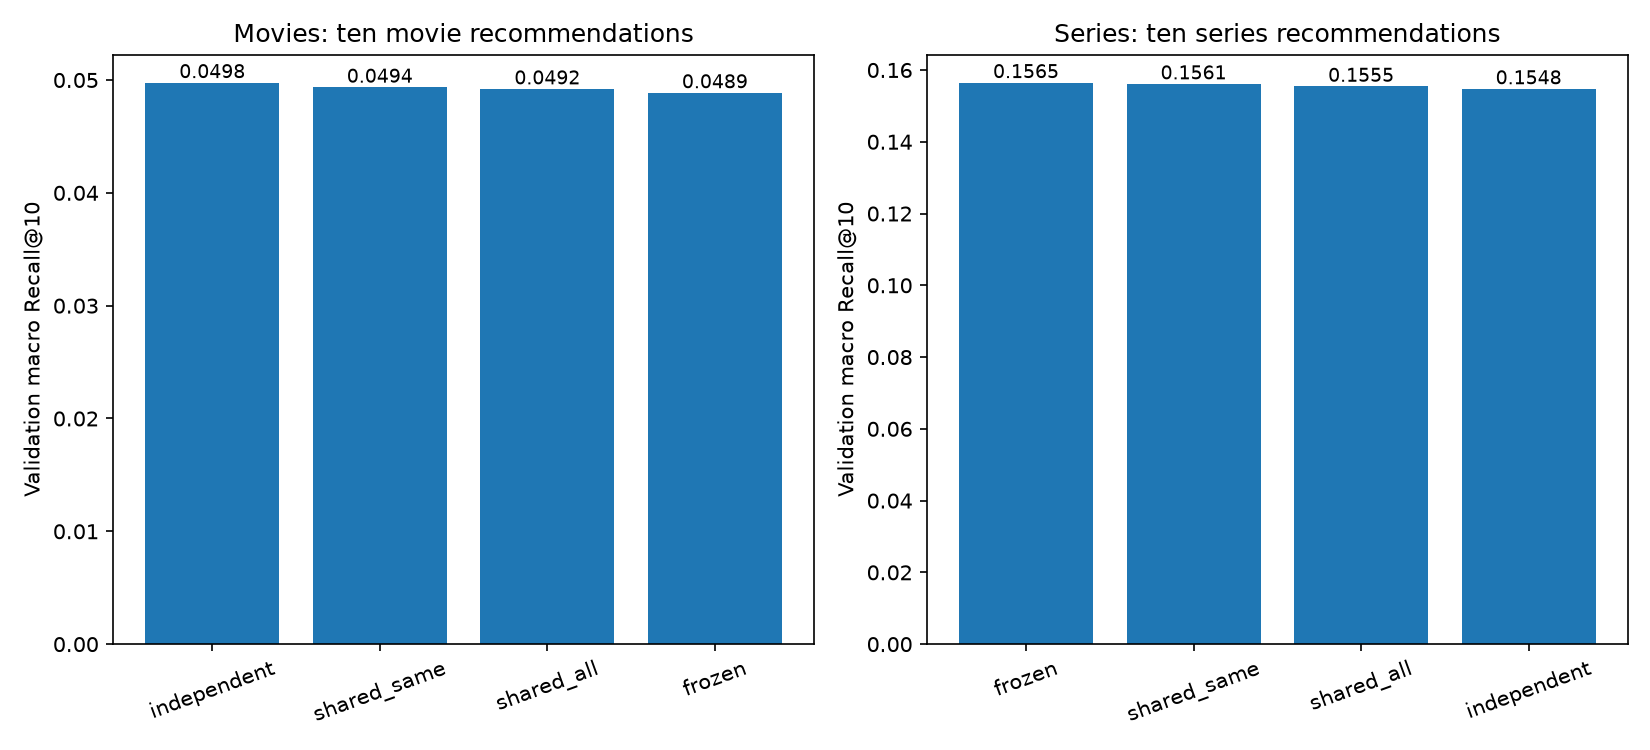

In [8]:
from IPython.display import Image

display(Image(filename=str(OUTPUT / 'separate_rankers_comparison.png')))

## Artifacts and remaining limits

Outputs are saved under [the notebook-19 results folder](../data/processed/notebook19_filmaffinity/). Earlier notebooks and the app are not modified. The helper records source identities and selection settings so the reported experiment can be reproduced.

- Unit labels outside the confirmed exclusions remain provisional. Review dates are publication-date proxies, and current metadata may postdate the ratings.
- Review-associated FilmAffinity feedback is a selected sample of preferences. The inherited established-user cohort is not a new-user population study.
- Train-only feature fitting and same-type candidate filtering are preserved. Unavailable relevant titles remain in denominators.
- Repeated validation and post-selection summaries are not an independent confirmation. Keep the reserved test untouched until the model, title-unit policy, candidate rules, and evaluation objectives are finalized.
- This experiment does not establish a general win over an LLM or direct comparability with earlier MovieLens scores. No API call, deployment, or app-model replacement is performed.

Use the measured within-type differences to decide how to tune the two rankers; use the equal-budget comparison to decide how the two lists should be presented.

In [9]:
print(f'Output directory: {OUTPUT}')
display(report.get('files', {}))

Output directory: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\processed\notebook19_filmaffinity


{'movie_leaderboard.csv': '0385d384d23e3f49d47c4641f76a5f52ffb27b3abb07dd2e5e2d9a5918e4df66',
 'tv_leaderboard.csv': '418321f095127ab73c418f48dade8e91570b7d13b9ccd4622d5b0c1b48a749ce',
 'family_ablation.csv': '818b2a0d5260b72dbb57e6b58517f6f0ddeaa50c509011020984ca4bd0f83928',
 'per_user.csv': 'a5394d284a9f9051207c2195b3c0316988dd40348ae7942d8464dcccf7539499',
 'history_bin_metrics.csv': '26a3f037bf6e689ff772f88b3225588374f725bc5e8eb3023ef5d79f62895146',
 'equal_budget_comparison.csv': 'fc67392d8e3272aa9394d7f34dcb66ef5efc18404d925b9dc95f13820a1ce4c7',
 'equal_budget_per_user.csv': '5a4dd0f3600926a66c5ef4793c51e9226ee318fd49dcd4ae907752f1105ed562',
 'recommendation_examples.csv': 'af5e6dc80defc5cecd8f819a5591d5611c6d75f3f8ef34fa48ca78f686d7e867',
 'study_plan.json': '8542f978a251b4462be6f3c16f728c1e3daaf2f809d55d58ddf2d7316a004781',
 'selection.json': '64eb6dd53024f8f14d0e80078db88e28c89ebe2a2c5c7c1587dc2d35289c5392',
 'trained_rankers.joblib': 'c29596e83af8e01369d9316dbe9d66e3a15d95512

## Compare history and fitting with alpha held constant

Each row below uses the same personal/popularity weight across the three fresh model families. This separates the shared-history ablation from independently fitting type vocabularies and priors. It does not remove the role of empty-profile popularity fallbacks; those counts are displayed alongside the metrics.


In [10]:
movie_rows = pd.read_csv(OUTPUT / 'movie_leaderboard.csv')
series_rows = pd.read_csv(OUTPUT / 'tv_leaderboard.csv')
fixed_alpha_rows = pd.concat([movie_rows, series_rows], ignore_index=True)
fixed_alpha_rows = fixed_alpha_rows.loc[fixed_alpha_rows['family'] != 'frozen'].sort_values(['kind', 'alpha', 'family'])
fixed_alpha_rows.to_csv(OUTPUT / 'fixed_alpha_comparison.csv', index=False)
display(fixed_alpha_rows[['kind', 'family', 'alpha', 'recall_at_10', 'ndcg_at_10', 'empty_profile_users']])
display(report['paired_intervals'])


,kind,family,alpha,recall_at_10,ndcg_at_10,empty_profile_users
12,movie,independent,0.00,0.031684,0.021822,114
10,movie,shared_all,0.00,0.031684,0.021822,82
11,movie,shared_same,0.00,0.031684,0.021822,114
7,movie,independent,0.25,0.035227,0.024662,114
9,movie,shared_all,0.25,0.035107,0.024614,82
8,movie,shared_same,0.25,0.035222,0.024644,114
5,movie,independent,0.50,0.044098,0.032814,114
4,movie,shared_all,0.50,0.044297,0.032939,82
6,movie,shared_same,0.50,0.043955,0.032977,114
0,movie,independent,1.00,0.049774,0.037441,114


{'movie': [{'metric': 'recall_at_10',
   'users': 3830,
   'mean_difference': 0.0008996684300017121,
   'lower_95': -0.0004529053089950034,
   'upper_95': 0.002358876850827972},
  {'metric': 'ndcg_at_10',
   'users': 3830,
   'mean_difference': 0.00035409113064553194,
   'lower_95': -0.000433964268105076,
   'upper_95': 0.0011289352156415777}],
 'whole_series': [{'metric': 'recall_at_10',
   'users': 972,
   'mean_difference': 0.0,
   'lower_95': 0.0,
   'upper_95': 0.0},
  {'metric': 'ndcg_at_10',
   'users': 972,
   'mean_difference': 0.0,
   'lower_95': 0.0,
   'upper_95': 0.0}]}

## Try the saved movie and TV rankers

The persisted bundle contains the independently selected pipelines: a movie-only fitted basis and the retained shared-history TV blend. A single profile can contain movie and whole-series ratings; each chosen pipeline uses the information it was evaluated with. Every rated candidate is excluded regardless of score.

This editable example uses FilmAffinity IDs for Breaking Bad, The Wire, Pulp Fiction and Blade Runner. Scores are illustrative rather than a real person's validation labels. Hundredths are accepted; profiles in this experiment still treat >=8 as likes. Both returns two ten-item lists, not a globally ordered top twenty.


In [11]:
import joblib
from scripts.filmaffinity_separate_rankers import recommend

fitted_rankers = joblib.load(OUTPUT / 'trained_rankers.joblib')
example_ratings = {
    'film489970': 9.25,  # Breaking Bad
    'film399474': 9.00,  # The Wire
    'film160882': 8.75,  # Pulp Fiction
    'film358476': 6.50,  # Blade Runner: excluded, not liked
}
separate_results = recommend(fitted_rankers, example_ratings, kind='both')
for label, frame in separate_results.items():
    expected_kind = 'movie' if label == 'movies' else 'whole_series'
    assert len(frame) == 10 and frame['item_id'].nunique() == 10
    assert frame['unit'].eq(expected_kind).all()
    assert not set(frame['item_id']) & (set(example_ratings) | set(fitted_rankers['excluded_item_ids']))
    print(f'{label.title()} for the illustrative profile:')
    display(frame)


Movies for the illustrative profile:
Series for the illustrative profile:


,item_id,title,original_title,year,unit,confidence,rank
0,film730528,El padrino. Parte II,The Godfather Part IIaka,1974,movie,medium,1
1,film161026,Cadena perpetua,The Shawshank Redemption,1994,movie,medium,2
2,film575149,Seven,Seven (Se7en),1995,movie,medium,3
3,film226427,El señor de los anillos: El retorno del rey,The Lord of the Rings: The Return of the King,2003,movie,medium,4
4,film568510,Snatch. Cerdos y diamantes,Snatchaka,2000,movie,medium,5
5,film536945,El club de la lucha,Fight Club,1999,movie,medium,6
6,film656153,La lista de Schindler,Schindler's List,1993,movie,medium,7
7,film346540,El padrino. Parte III,The Godfather Part IIIaka,1990,movie,medium,8
8,film518309,Infiltrados,The Departed,2006,movie,medium,9
9,film188896,El precio del poder,Scarface,1983,movie,medium,10


,item_id,title,original_title,year,unit,confidence,rank
0,film372160,Los Simpson,The Simpsons,1989,whole_series,high,1
1,film370639,Perdidos (Lost),Lostaka,2004,whole_series,high,2
2,film402150,Los Soprano,The Sopranos,1999,whole_series,high,3
3,film745443,Friends,Friends,1994,whole_series,high,4
4,film482444,Dexter,Dexter,2006,whole_series,high,5
5,film585998,A dos metros bajo tierra,Six Feet Under,2001,whole_series,high,6
6,film640188,Hermanos de sangre,Band of Brothers,2001,whole_series,medium,7
7,film596790,Mad Men,Mad Men,2007,whole_series,high,8
8,film234364,The Big Bang Theory,The Big Bang Theoryaka,2007,whole_series,high,9
9,film781297,Fargo,Fargo,2014,whole_series,medium,10
